In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Add files up one level to the path
import sys
sys.path.append("../..")

import scipy.sparse as sps

import jlinops


import sys
import os

# Go three directories up
# current_dir = os.path.dirname(os.getcwd())
# three_dirs_up = os.path.abspath(os.path.join(current_dir, '..', '..', ".."))
# sys.path.append(three_dirs_up)


from msolver import MMGKS, IASGKS, VanillaGKS

#from pinv import CGWeightedNeumann2DPinvOperatorGPU

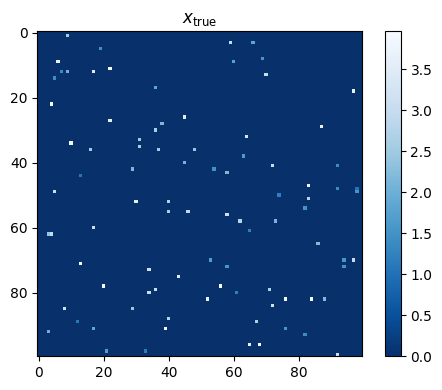

In [11]:
# Set example size
M, N = 100, 100
img_shape = (M,N)
n = M*N

# Draw random image
np.random.seed(1)
p = np.random.binomial(1, 0.01, size=img_shape).astype(np.float64)
q = np.random.uniform(low=1, high=4, size=img_shape).astype(np.float64)
ground_truth = (p*q).flatten()
x_true = ground_truth.copy()

plt.figure(figsize=(5,4))
plt.imshow(ground_truth.reshape(img_shape), cmap="Blues_r")
plt.title("$x_{\\text{true}}$")
plt.colorbar()
plt.tight_layout()
plt.show()

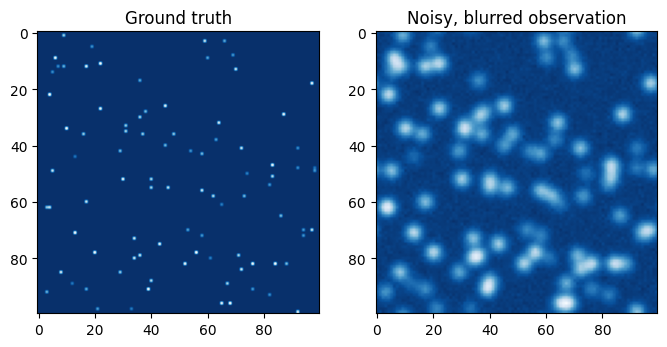

In [15]:
# Make blurring operator
blur_sigma = np.array(2.0).astype(np.float64) # standard deviation of the blur
A = jlinops.Gaussian2DBlurOperator(img_shape, blur_sigma=2.0)

# Generate synthetic data
np.random.seed(0)
b_true = A @ ground_truth
noise_vec = np.random.normal(size=A.shape[0])
noise_vec /= np.linalg.norm(noise_vec)
noise_level_sigma = 0.08
noise_vec *= noise_level_sigma*np.linalg.norm(b_true)
noise_var = ( (noise_level_sigma*np.linalg.norm(b_true) )**2 ) / A.shape[0]
b = b_true + noise_vec
#b =  b_true + noise_sigma*np.random.normal(size=A.shape[0])


# # Blurred image
# blurred_image = A.matvec_shaped(image)

# # Add some noise
# noise_sigma = 0.03*np.amax(blurred_image)
# noise_var = noise_sigma**2
# noisy_image = blurred_image + noise_sigma*np.random.normal(size=image.shape)
# b = noisy_image.flatten()

# Plot
fig, axs = plt.subplots(1, 2, figsize=(8,5))
axs[0].imshow(ground_truth.reshape(img_shape), cmap="Blues_r")
axs[0].set_title("Ground truth")
axs[1].imshow(b.reshape(img_shape), cmap="Blues_r")
axs[1].set_title("Noisy, blurred observation")
fig.show()

# Set up solvers

In [16]:
# Set method
method = "dp"

#Lmat = jlinops.build_neumann2d_sparse_matrix(img_shape)
#L = jlinops.Neumann2D(img_shape)
L = jlinops.IdentityOperator((n,n))

def Lpinv_factory(w):
    return jlinops.DiagonalOperator(w)

K = None


q = 1.0
epsilon = 1e-3
weight_params = {
    "q": q,
    "epsilon": epsilon,
}


# Build solvers
gks_solver = VanillaGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=None, img_shape=img_shape)
mmgks_solver = MMGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)

# Run all solvers

In [ ]:
vdata = gks_solver.solve(n_iter=50, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-14, lambdah_max=1e7,
                                    regparam=method, x_true=x_true.flatten(), weight_params={},
                                    regparam_kwargs={"eta":1.01})

In [ ]:
data = mmgks_solver.solve(n_iter=50, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-14, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth.flatten(), weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01})

pdata = mmgks_solver.solve_with_priorconditioning(n_iter=50, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-14, lambdah_max=1e7,
                                                 regparam=method, x_true=ground_truth, weight_params=weight_params,
                                                 regparam_kwargs={"eta":1.01})

# Plot

# Old

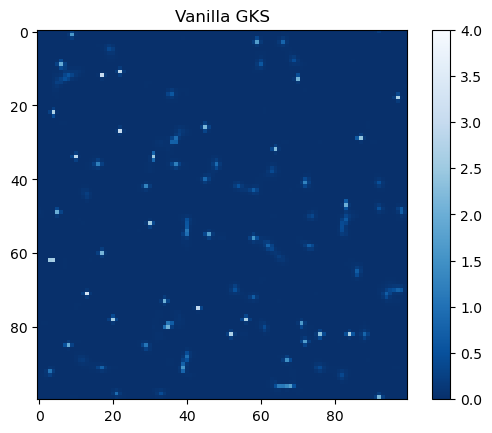

In [23]:
plt.imshow(data["x"].reshape((M,N)), cmap="Blues_r", vmin=0, vmax=4)
plt.title("Vanilla GKS")
plt.colorbar()
plt.show()

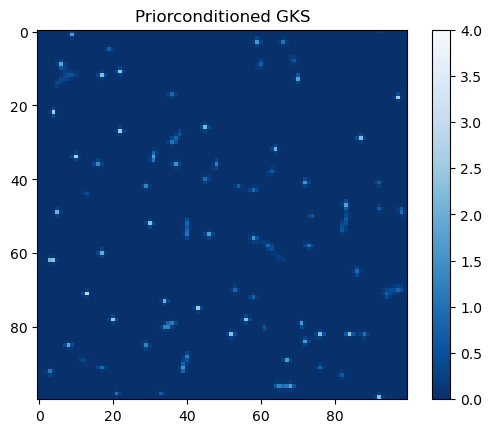

In [29]:
plt.imshow(pdata["x"].reshape((M,N)), cmap="Blues_r", vmin=0, vmax=4)
plt.title("Priorconditioned GKS")
plt.colorbar()
plt.show()

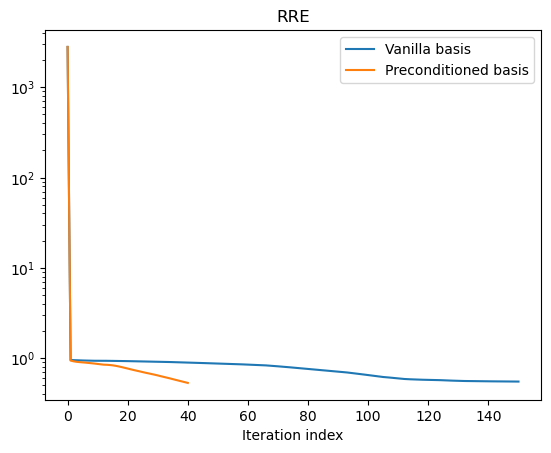

In [27]:
plt.semilogy(data["rre_history"], label="Vanilla basis")
plt.semilogy(pdata["rre_history"], label="Preconditioned basis")
plt.title("RRE")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

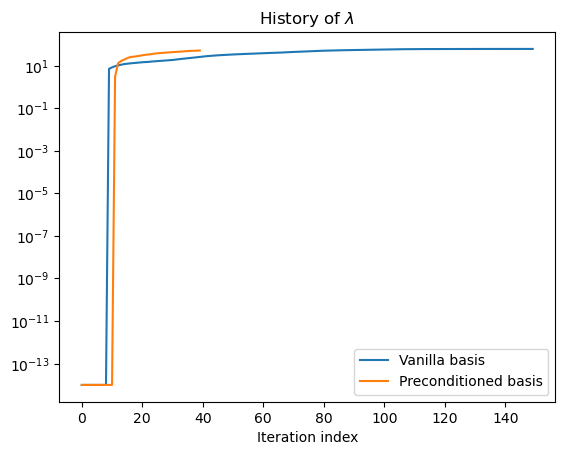

In [26]:
plt.semilogy(data["lambda_history"], label="Vanilla basis")
plt.semilogy(pdata["lambda_history"], label="Preconditioned basis")
plt.title("History of $\\lambda$")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

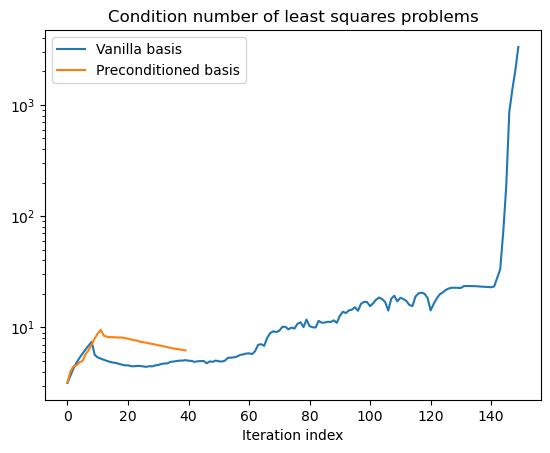

In [25]:
plt.semilogy(data["cond_ests"], label="Vanilla basis")
plt.semilogy(pdata["cond_ests"], label="Preconditioned basis")
plt.title("Condition number of least squares problems")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

# IAS example

In [77]:
n_iters = 200

# weight_params = {
#     "hyperpr_r": 1.0,
#     "hyperpr_beta": 1.5 + 1e-9,
# }

weight_params = {
    "hyperpr_r": -1.0,
    "hyperpr_beta": 1.0,
}

In [80]:
# Set method
method = "dp"

# Build solver
iasgks_solver = IASGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)


# # Run the solver
# ias_data = ias_solver.solve(n_iter=n_iters, init_dim=5, hyperpr_r=hyperpr_r, hyperpr_beta=hyperpr_beta, x_true=ground_truth, regparam=method, regparam_fixed=1e0)


In [81]:
data = iasgks_solver.solve(n_iter=60, init_dim=5, x0=None, lambdah0=1e0, lambdah_max=1e7,
                                    regparam=method, x_true=image.flatten(), weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01})

pdata = iasgks_solver.solve_with_priorconditioning(n_iter=60, init_dim=5, x0=None, lambdah0=1e0, lambdah_max=1e7,
                                                 regparam="dp", x_true=image.flatten(), weight_params=weight_params,
                                                 regparam_kwargs={"eta":1.01})

1e-06
1e-06
1e-06
1e-06
1e-06
1e-06
1e-06
1e-06
1e-06
9.467149935847033
27.118985709168715
45.65587490365957
62.362043251342456
77.59662013253595
92.26863261612445
105.31007822104877
116.12223823864205
124.7868006466447
135.31419179784382
146.85623521033858
160.0401895640133
174.7074343573647
195.75029356445472
231.28069466728147
273.7620994787222
316.57489033725875
364.2742096611241
418.62611109737463
489.29639712301037
537.1812694951551
595.4335665710255
629.1451520584915
645.2171415778886
649.6444334574664
718.9600418002854
744.2526025354924
827.122338413305
861.8415008305542
931.2425012132194
921.9479420670381
1002.0984977847224
1017.4001040720814
994.7871964032231
1078.547984861973
1099.9445920809706
1069.9673805481107
1161.1047683127128
1044.0451718306192
1351.66060160509
853.0075220817574
1091.240119308039
922.4922704970847
1078.8848563445442
1029.0609452813471
951.5734888277361
1010.3324769321263
954.44283372963
1030.0281239186304
965.1086180010684
1004.0394154760099


1e-06
1e-06
1e-06
1e-06
1e-06
1e-06
1e-06
1e-06
1e-06
1e-06
13.870406721749893
1e-06
24.725919500613795
1e-06
30.49741109612299
53.556704388541895
56.660574954361984
94.46630552345485
144.60342068006463
180.08376256099393
252.09088559241758
301.8974116802701
341.70850329382426
240.8774744674166
72.70196750623187
170.40159679391914
264.0003977389446
260.9680711584005
1e-06
33.80998109026222
78.41403689437186
147.52209551987033
262.1390927504261
480.11986112970294
749.1477577180548
559.3700925891021
1e-06
35.984501928540595
87.72594649760858
180.30731228033918
381.8000762248068
714.9065887148595
709.5286775231243
245.32985494838567
295.5952500382791
292.7938322639731
249.28903575269015
248.00914673448654
289.78829959730916
384.44978488082705
227.37803675872274
471.42888350033354
427.4108350835809
490.09984143192906
266.6074254346446
513.5734149812935
384.2591975448697
698.2042103246083
96.6092536640195
652.694540580394


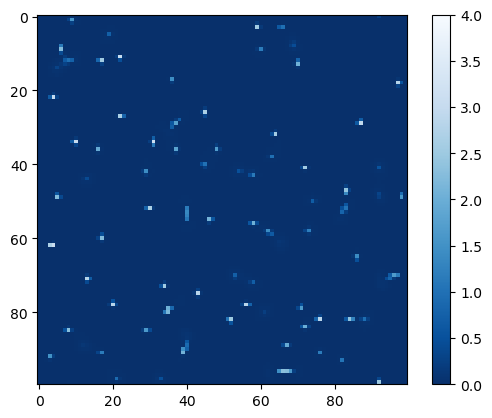

In [82]:
plt.imshow(data["x"].reshape((M,N)), cmap="Blues_r", vmin=0, vmax=4)
plt.colorbar()
plt.show()

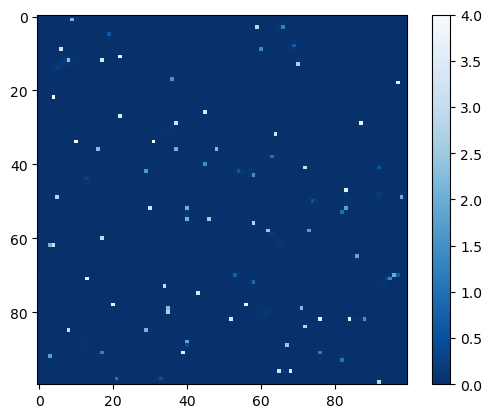

In [83]:
plt.imshow(pdata["x"].reshape((M,N)), cmap="Blues_r", vmin=0, vmax=4)
plt.colorbar()
plt.show()

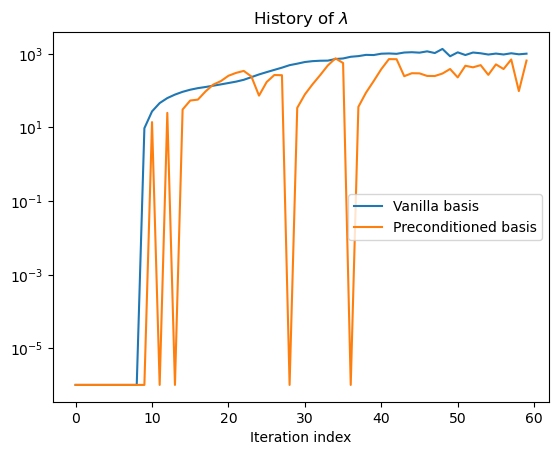

In [84]:
plt.semilogy(data["lambda_history"], label="Vanilla basis")
plt.semilogy(pdata["lambda_history"], label="Preconditioned basis")
plt.title("History of $\\lambda$")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

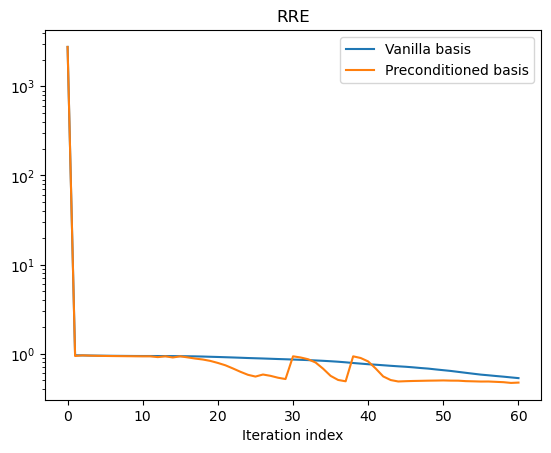

In [85]:
plt.semilogy(data["rre_history"], label="Vanilla basis")
plt.semilogy(pdata["rre_history"], label="Preconditioned basis")
plt.title("RRE")
plt.xlabel("Iteration index")
plt.legend()
plt.show()